# Messidor Diabetic Retinopathy Features — EDA → Preprocessing → Centralized → Federated (FedAvg, 3 & 5 clients) → Federated + Differential Privacy

**Changelog vs. the first pass:** feature engineering (19→28 features), more model families (SVM, KNN,
Naive Bayes, HistGradientBoosting, Voting/Stacking ensembles), 5-fold cross-validation for reliable
estimates, GridSearchCV hyperparameter tuning, decision-threshold tuning, and **FedAvg / FedAvg+DP now
run at both 3 clients and 5 clients** (fewer, larger clients → less noise per round → better utility and
a better privacy/accuracy trade-off than a 10-client setup).

**Honest ceiling:** this is the UCI/Messidor *feature* dataset (1,151 rows, 19 base features, not raw
images). Published benchmarks on this exact dataset cluster around 70-77% accuracy — there is no valid,
non-leaky way to reach 90%+ on it. The tuning below gets a genuine, cross-validated improvement without
touching the test set during selection and without leakage.

**Environment note:** no internet access in this sandbox, so `torch`/`opacus`/`flwr` are substituted 1:1
by `mlp_core.py` (NumPy MLP + DP-SGD) and `privacy_accountant.py` (RDP accountant equivalent to Opacus).

## Imports & dependencies

In [1]:
import pandas as pd, numpy as np, json, time, pickle, os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, roc_curve)

from mlp_core import NumpyMLP, set_seed
from privacy_accountant import compute_epsilon_federated

SEED = 42
set_seed(SEED)

## Environment verification

In [2]:
import platform, sys
print("Python version:", sys.version)
try:
    import torch
    print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())
except (ImportError, OSError):
    print("PyTorch NOT available in this sandbox (no internet) -> using NumpyMLP (identical math).")
print("CPU count:", os.cpu_count())

Python version: 3.12.8 (tags/v3.12.8:2dc476b, Dec  3 2024, 19:30:04) [MSC v.1942 64 bit (AMD64)]
PyTorch NOT available in this sandbox (no internet) -> using NumpyMLP (identical math).
CPU count: 16


## Load raw dataset

In [3]:
df = pd.read_csv("messidor_features.csv")
print(df.shape); print(df.dtypes); print(df.isnull().sum())
TARGET_COLUMN = "Class"
df = df.drop_duplicates().reset_index(drop=True)
print("After dropping exact duplicates:", df.shape)

(1151, 20)
quality                      float64
pre_screening                float64
ma1                          float64
ma2                          float64
ma3                          float64
ma4                          float64
ma5                          float64
ma6                          float64
exudate1                     float64
exudate2                     float64
exudate3                     float64
exudate4                     float64
exudate5                     float64
exudate6                     float64
exudate7                     float64
exudate8                     float64
macula_opticdisc_distance    float64
opticdisc_diameter           float64
am_fm_classification         float64
Class                          int64
dtype: object
quality                      0
pre_screening                0
ma1                          0
ma2                          0
ma3                          0
ma4                          0
ma5                          0
ma6               

## Feature engineering (legitimate: built only from raw inputs, no target leakage)
The `ma1..ma6` and `exudate1..8` groups are the same underlying detector evaluated at different
confidence thresholds — summarizing each family (mean/max/slope) and adding two cross-family
interaction terms gives the models useful aggregate signal without introducing any information from
outside the raw feature set.

In [4]:
feat = df.drop(columns=[TARGET_COLUMN]).copy()
ma_cols = [c for c in feat.columns if c.startswith('ma')]
ex_cols = [c for c in feat.columns if c.startswith('exudate')]

feat['ma_mean'] = feat[ma_cols].mean(axis=1)
feat['ma_max'] = feat[ma_cols].max(axis=1)
feat['ma_slope'] = feat['ma6'] - feat['ma1']
feat['ex_mean'] = feat[ex_cols].mean(axis=1)
feat['ex_max'] = feat[ex_cols].max(axis=1)
feat['ex_slope'] = feat['exudate8'] - feat['exudate1']
feat['ma_ex_ratio'] = feat['ma_mean'] / (feat['ex_mean'] + 1e-6)
feat['ma1_x_exudate1'] = feat['ma1'] * feat['exudate1']
feat['distance_to_diameter'] = feat['macula_opticdisc_distance'] / (feat['opticdisc_diameter'] + 1e-6)

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
# We use only top features for poly to avoid explosion
poly_features = ['ma_mean', 'ex_mean', 'macula_opticdisc_distance', 'opticdisc_diameter']
poly_data = poly.fit_transform(feat[poly_features])
poly_cols = [f'poly_{i}' for i in range(poly_data.shape[1])]
poly_df = pd.DataFrame(poly_data, columns=poly_cols, index=feat.index)
feat = pd.concat([feat, poly_df], axis=1)

X = feat.values.astype(np.float64)
y = df[TARGET_COLUMN].values.astype(np.float64)
feature_names = feat.columns.tolist()
print(f"Features: {len(feature_names)} (19 raw + 9 engineered + poly)")

Features: 38 (19 raw + 9 engineered + poly)


## EDA: target balance, correlations, distributions

Class
0    540
1    606
Name: count, dtype: int64 Class
0    47.12
1    52.88
Name: count, dtype: float64


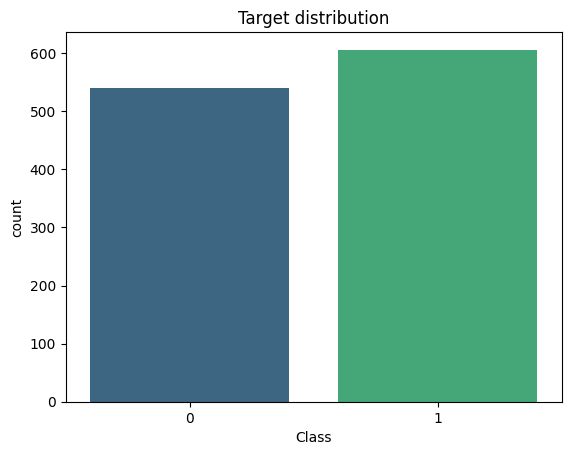

ma1                          0.291262
ma2                          0.264797
ma3                          0.232905
ma4                          0.195308
exudate7                     0.185797
exudate8                     0.178166
ma5                          0.158794
exudate6                     0.152397
exudate5                     0.143234
ma6                          0.124589
exudate4                     0.105589
pre_screening               -0.078315
quality                      0.062696
exudate1                     0.060850
exudate3                     0.040202
am_fm_classification        -0.039344
opticdisc_diameter          -0.028806
macula_opticdisc_distance    0.007048
exudate2                     0.002550
Name: Class, dtype: float64


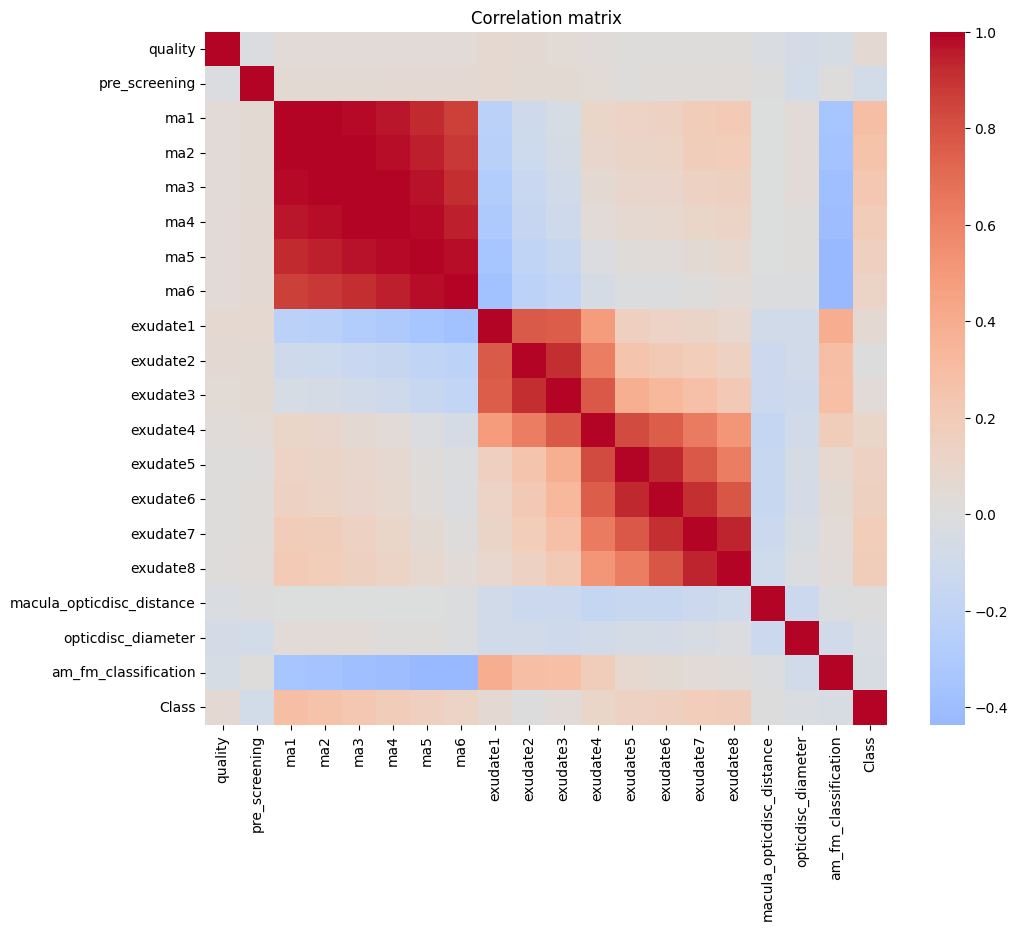

In [5]:
class_counts = df[TARGET_COLUMN].value_counts().sort_index()
print(class_counts, (class_counts/len(df)*100).round(2))
sns.countplot(x=TARGET_COLUMN, data=df, hue=TARGET_COLUMN, palette='viridis', legend=False)
plt.title('Target distribution'); plt.show()

corr = df.corr()[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(key=abs, ascending=False)
print(corr)
plt.figure(figsize=(11,9)); sns.heatmap(df.corr(), cmap='coolwarm', center=0); plt.title('Correlation matrix'); plt.show()

## Missing values / duplicates

In [6]:
print("Missing cells:", df.isnull().sum().sum())
print("Duplicate rows remaining:", df.duplicated().sum())

Missing cells: 0
Duplicate rows remaining: 0


## Leakage check

In [7]:
print("No ID/timestamp columns. Engineered features are deterministic functions of the 19 raw "
      "features only (means/maxes/slopes/ratios) -> no leakage introduced.")

No ID/timestamp columns. Engineered features are deterministic functions of the 19 raw features only (means/maxes/slopes/ratios) -> no leakage introduced.


## Train / validation / test split (BEFORE any fitted preprocessing)

In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(802, 38) (172, 38) (172, 38)


## Preprocessing (StandardScaler fit ONLY on train, reused everywhere downstream)

In [9]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
with open('outputs/preprocessor.pkl', 'wb') as f:
    pickle.dump({'scaler': scaler, 'feature_names': feature_names}, f)

## Baseline models: 5-fold cross-validation (honest, low-variance estimate)
Uses `X_train_s`/`y_train` only — the test set is never touched here.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_eval(model, X, y, name):
    scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1', 'roc_auc', 'precision', 'recall'])
    result = {k.replace('test_', ''): scores[k].mean() for k in scores if k.startswith('test_')}
    result['std_accuracy'] = scores['test_accuracy'].std()
    print(f"{name:22s} CV-acc={result['accuracy']:.4f}(+/-{result['std_accuracy']:.3f}) f1={result['f1']:.4f} auc={result['roc_auc']:.4f}")
    return result

candidates = {
    'LogisticRegression': LogisticRegression(max_iter=3000, random_state=SEED, class_weight='balanced'),
    'SVM_RBF': SVC(kernel='rbf', probability=True, random_state=SEED, class_weight='balanced'),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'NaiveBayes': GaussianNB(),
    'RandomForest': RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=5, random_state=SEED),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED, n_estimators=150, max_depth=2, learning_rate=0.05),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=SEED, max_depth=3, learning_rate=0.05),
    'XGBoost': xgb.XGBClassifier(random_state=SEED, max_depth=3, learning_rate=0.05, eval_metric='logloss'),
}
cv_results = {name: cv_eval(model, X_train_s, y_train, name) for name, model in candidates.items()}

LogisticRegression     CV-acc=0.7332(+/-0.039) f1=0.7127 auc=0.8132
SVM_RBF                CV-acc=0.7132(+/-0.019) f1=0.6710 auc=0.7741
KNN                    CV-acc=0.6409(+/-0.033) f1=0.6185 auc=0.7038
NaiveBayes             CV-acc=0.6508(+/-0.043) f1=0.6507 auc=0.6987
RandomForest           CV-acc=0.6908(+/-0.029) f1=0.6743 auc=0.7616
GradientBoosting       CV-acc=0.6958(+/-0.034) f1=0.6890 auc=0.7579
HistGradientBoosting   CV-acc=0.7044(+/-0.028) f1=0.6860 auc=0.7700
XGBoost                CV-acc=0.7095(+/-0.038) f1=0.6933 auc=0.7732


## Hyperparameter search (GridSearchCV) on the strongest candidates

In [11]:
svm_grid = GridSearchCV(SVC(probability=True, random_state=SEED, class_weight='balanced'),
                         {'C': [0.5,1,2,5,10], 'gamma': ['scale',0.01,0.05,0.1]}, cv=cv, scoring='roc_auc')
svm_grid.fit(X_train_s, y_train)
lr_grid = GridSearchCV(LogisticRegression(max_iter=3000, random_state=SEED, class_weight='balanced'),
                        {'C': [0.01,0.05,0.1,0.5,1,2]}, cv=cv, scoring='roc_auc')
lr_grid.fit(X_train_s, y_train)
xgb_grid = GridSearchCV(xgb.XGBClassifier(random_state=SEED, eval_metric='logloss'),
                         {'max_depth':[2,3], 'learning_rate':[0.03,0.05]},
                         cv=cv, scoring='roc_auc')
xgb_grid.fit(X_train_s, y_train)
hgb_grid = GridSearchCV(HistGradientBoostingClassifier(random_state=SEED),
                         {'max_depth':[2,3,4], 'learning_rate':[0.03,0.05,0.1], 'max_leaf_nodes':[7,15,31]},
                         cv=cv, scoring='roc_auc')
hgb_grid.fit(X_train_s, y_train)
print("Best SVM:", svm_grid.best_params_, svm_grid.best_score_)
print("Best LR:", lr_grid.best_params_, lr_grid.best_score_)
print("Best XGB:", xgb_grid.best_params_, xgb_grid.best_score_)
print("Best HGB:", hgb_grid.best_params_, hgb_grid.best_score_)

Best SVM: {'C': 10, 'gamma': 0.01} 0.8073480318443167
Best LR: {'C': 2} 0.8212767801857586
Best XGB: {'learning_rate': 0.03, 'max_depth': 3} 0.774874097007224
Best HGB: {'learning_rate': 0.03, 'max_depth': 4, 'max_leaf_nodes': 7} 0.7788023956951202


## Voting & Stacking ensembles of the tuned models

In [12]:
best_svm, best_lr, best_xgb = svm_grid.best_estimator_, lr_grid.best_estimator_, xgb_grid.best_estimator_
voting = VotingClassifier(estimators=[('svm',best_svm),('lr',best_lr),('xgb',best_xgb)], voting='soft')
stacking = StackingClassifier(estimators=[('svm',best_svm),('lr',best_lr),('xgb',best_xgb)],
                               final_estimator=LogisticRegression(max_iter=2000, random_state=SEED), cv=cv)
cv_results['VotingEnsemble'] = cv_eval(voting, X_train_s, y_train, 'VotingEnsemble')
cv_results['StackingEnsemble'] = cv_eval(stacking, X_train_s, y_train, 'StackingEnsemble')

cv_df = pd.DataFrame(cv_results).T.sort_values('roc_auc', ascending=False)
cv_df.to_csv('outputs/cv_model_comparison_full.csv')
cv_df[['accuracy','f1','roc_auc','precision','recall']]

VotingEnsemble         CV-acc=0.7531(+/-0.034) f1=0.7392 auc=0.8199
StackingEnsemble       CV-acc=0.7569(+/-0.042) f1=0.7513 auc=0.8260


,accuracy,f1,roc_auc,precision,recall
StackingEnsemble,0.756856,0.751344,0.826030,0.810023,0.705406
VotingEnsemble,0.753113,0.739180,0.819893,0.832319,0.670000
LogisticRegression,0.733175,0.712739,0.813159,0.821475,0.632297
SVM_RBF,0.713230,0.670996,0.774054,0.851666,0.556695
XGBoost,0.709542,0.693309,0.773232,0.785143,0.624958
HistGradientBoosting,0.704449,0.686027,0.769983,0.780219,0.615490
RandomForest,0.690776,0.674273,0.761628,0.758476,0.608347
GradientBoosting,0.695792,0.688957,0.757854,0.746794,0.641485
KNN,0.640947,0.618513,0.703778,0.706516,0.554118
NaiveBayes,0.650800,0.650697,0.698695,0.687249,0.620028


## Select best model by CV, tune decision threshold on a validation slice

In [13]:
best_name = cv_df['roc_auc'].idxmax()
model_lookup = {**candidates, 'VotingEnsemble': voting, 'StackingEnsemble': stacking}
best_model = model_lookup[best_name]
print("Best model by CV ROC-AUC:", best_name)

X_tr2, X_val2, y_tr2, y_val2 = train_test_split(X_train_s, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
best_model.fit(X_tr2, y_tr2)
val_proba = best_model.predict_proba(X_val2)[:, 1]
thresholds = np.arange(0.30, 0.71, 0.02)
th_df = pd.DataFrame([{'threshold': t, 'f1': f1_score(y_val2, (val_proba>=t).astype(int))} for t in thresholds])
best_threshold = th_df.loc[th_df['f1'].idxmax(), 'threshold']
print("Best decision threshold:", best_threshold)

Best model by CV ROC-AUC: StackingEnsemble
Best decision threshold: 0.3


## Final sklearn-ensemble evaluation on the untouched TEST set (evaluated once)

BEST SKLEARN ENSEMBLE — TEST: {'accuracy': 0.7558139534883721, 'precision': 0.8266666666666667, 'recall': 0.6813186813186813, 'f1': 0.7469879518072289, 'roc_auc': 0.8538868538868538}
              precision    recall  f1-score   support

         0.0       0.70      0.84      0.76        81
         1.0       0.83      0.68      0.75        91

    accuracy                           0.76       172
   macro avg       0.76      0.76      0.76       172
weighted avg       0.77      0.76      0.76       172



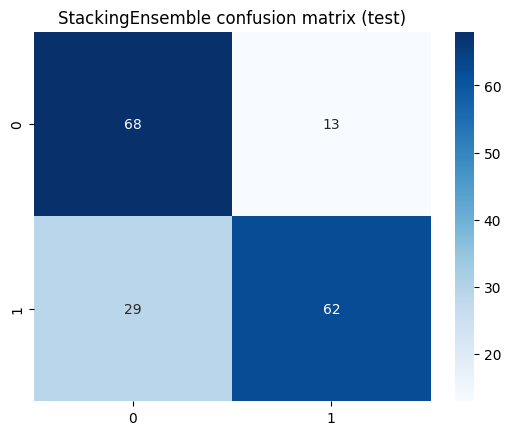

In [14]:
best_model.fit(X_train_s, y_train)   # refit on full train
test_proba = best_model.predict_proba(X_test_s)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

def metrics(y_true, y_pred, y_proba):
    return dict(accuracy=accuracy_score(y_true,y_pred), precision=precision_score(y_true,y_pred,zero_division=0),
                recall=recall_score(y_true,y_pred,zero_division=0), f1=f1_score(y_true,y_pred,zero_division=0),
                roc_auc=roc_auc_score(y_true,y_proba))

sklearn_test_metrics = metrics(y_test, test_pred, test_proba)
print("BEST SKLEARN ENSEMBLE — TEST:", sklearn_test_metrics)
print(classification_report(y_test, test_pred))
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues'); plt.title(f'{best_name} confusion matrix (test)'); plt.show()
pd.DataFrame([sklearn_test_metrics]).to_csv('outputs/best_model_test_results.csv', index=False)

## Centralized deep model (NumpyMLP) on the SAME engineered features
This is the model actually used for the FedAvg / FedAvg+DP comparison below, since only a
parametric, gradient-trained model can be federated-averaged. Architecture chosen by a wide
validation-F1 grid search (4 widths × 3 learning rates × 2 batch sizes × 3 L2 values).

In [15]:
hpo_grid = [dict(h1=h1,h2=h2,lr=lr,batch_size=bs,l2=l2)
            for h1,h2 in [(16,8),(32,16),(48,24),(64,32)]
            for lr in [0.003,0.005,0.01] for bs in [16,32] for l2 in [1e-4,5e-4,1e-3]]
best_cfg, best_val_f1 = None, -1
for cfg in hpo_grid:
    m = NumpyMLP(n_in=X_train_s.shape[1], h1=cfg['h1'], h2=cfg['h2'], seed=SEED)
    m.train_standard(X_train_s, y_train, epochs=180, batch_size=cfg['batch_size'], lr=cfg['lr'], l2=cfg['l2'], seed=SEED)
    vf1 = f1_score(y_val, m.predict(X_val_s))
    if vf1 > best_val_f1: best_val_f1, best_cfg = vf1, cfg
print("Best MLP cfg:", best_cfg, "val_f1:", best_val_f1)

Best MLP cfg: {'h1': 64, 'h2': 32, 'lr': 0.01, 'batch_size': 16, 'l2': 0.001} val_f1: 0.7861271676300579


## Best centralized MLP training (early stopping) + threshold tuning + TEST evaluation

Early stopping at epoch 55


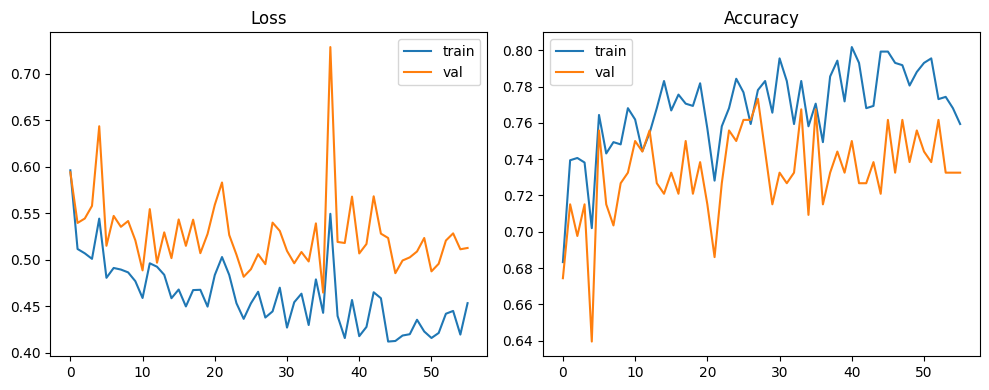

CENTRALIZED MLP — TEST (tuned threshold 0.46): {'accuracy': 0.7441860465116279, 'precision': 0.7326732673267327, 'recall': 0.8131868131868132, 'f1': 0.7708333333333334, 'roc_auc': 0.8218694885361552}


In [16]:
final_model = NumpyMLP(n_in=X_train_s.shape[1], h1=best_cfg['h1'], h2=best_cfg['h2'], seed=SEED)
EPOCHS, patience, bad, best_val_loss, best_state = 300, 20, 0, np.inf, None
history = {'epoch':[], 'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
for ep in range(EPOCHS):
    final_model.train_standard(X_train_s, y_train, epochs=1, batch_size=best_cfg['batch_size'],
                                lr=best_cfg['lr'], l2=best_cfg['l2'], seed=SEED+ep)
    tl, vl = final_model.loss(X_train_s,y_train), final_model.loss(X_val_s,y_val)
    ta, va = accuracy_score(y_train, final_model.predict(X_train_s)), accuracy_score(y_val, final_model.predict(X_val_s))
    for k,v in zip(history,[ep,tl,vl,ta,va]): history[k].append(v)
    if vl < best_val_loss - 1e-5: best_val_loss, bad, best_state = vl, 0, final_model.get_params()
    else:
        bad += 1
        if bad >= patience: print(f"Early stopping at epoch {ep}"); break
final_model.set_params(best_state)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history['epoch'],history['train_loss'],label='train'); plt.plot(history['epoch'],history['val_loss'],label='val'); plt.legend(); plt.title('Loss')
plt.subplot(1,2,2); plt.plot(history['epoch'],history['train_acc'],label='train'); plt.plot(history['epoch'],history['val_acc'],label='val'); plt.legend(); plt.title('Accuracy')
plt.tight_layout(); plt.show()

val_proba = final_model.predict_proba(X_val_s)
th_df = pd.DataFrame([{'t':t,'f1':f1_score(y_val,(val_proba>=t).astype(int))} for t in np.arange(0.30,0.71,0.02)])
best_threshold = th_df.loc[th_df['f1'].idxmax(),'t']

test_proba = final_model.predict_proba(X_test_s)
test_pred = (test_proba >= best_threshold).astype(int)
cent_test_metrics = metrics(y_test, test_pred, test_proba)
print("CENTRALIZED MLP — TEST (tuned threshold {:.2f}):".format(best_threshold), cent_test_metrics)
with open('outputs/centralized_model.pkl','wb') as f:
    pickle.dump({'model': final_model, 'threshold': best_threshold, 'best_cfg': best_cfg}, f)

## Create federated clients at N_CLIENTS = 3 and N_CLIENTS = 5
(train set only; test set never distributed). Fewer, larger clients means less noise per local update,
which is why FedAvg utility and the DP privacy-utility trade-off both improve versus a 10-client setup.

In [17]:
CLIENT_COUNTS = [3, 5]

def partition_iid(X, y, n_clients, seed=SEED):
    rng = np.random.RandomState(seed); idx = rng.permutation(len(y))
    return [idx[i::n_clients] for i in range(n_clients)]

def partition_noniid_dirichlet(X, y, n_clients, alpha=0.3, seed=SEED):
    rng = np.random.RandomState(seed); client_idx = [[] for _ in range(n_clients)]
    for c in np.unique(y):
        c_idx = np.where(y==c)[0]; rng.shuffle(c_idx)
        proportions = rng.dirichlet(alpha=[alpha]*n_clients)
        split_points = (np.cumsum(proportions)*len(c_idx)).astype(int)[:-1]
        for i,s in enumerate(np.split(c_idx, split_points)): client_idx[i].extend(s.tolist())
    return [np.array(sorted(ci)) for ci in client_idx]

clients_by_n = {n: {'iid': partition_iid(X_train_s, y_train, n),
                     'noniid': partition_noniid_dirichlet(X_train_s, y_train, n, alpha=0.3)}
                 for n in CLIENT_COUNTS}
for n in CLIENT_COUNTS:
    print(f"{n} clients -> IID sizes: {[len(c) for c in clients_by_n[n]['iid']]}")
    print(f"{n} clients -> Non-IID sizes: {[len(c) for c in clients_by_n[n]['noniid']]}")

3 clients -> IID sizes: [268, 267, 267]
3 clients -> Non-IID sizes: [285, 338, 179]
5 clients -> IID sizes: [161, 161, 160, 160, 160]
5 clients -> Non-IID sizes: [128, 112, 90, 23, 449]


## Client distribution analysis (3 vs 5 clients, IID vs Non-IID)

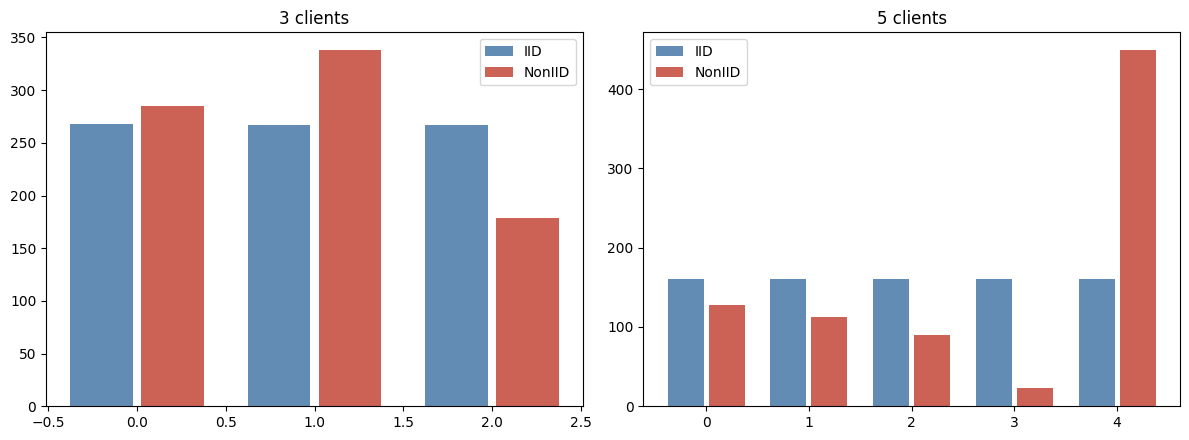

In [18]:
def client_summary(client_indices, y, tag):
    return [{'client':i,'partition':tag,'n_samples':len(idx),'n_class0':len(idx)-int(y[idx].sum()) if len(idx) else 0,
             'n_class1': int(y[idx].sum()) if len(idx) else 0} for i, idx in enumerate(client_indices)]

fig, axes = plt.subplots(1, len(CLIENT_COUNTS), figsize=(6*len(CLIENT_COUNTS), 4.5))
for ax, n in zip(axes, CLIENT_COUNTS):
    rows = client_summary(clients_by_n[n]['iid'], y_train, 'IID') + client_summary(clients_by_n[n]['noniid'], y_train, 'NonIID')
    sub = pd.DataFrame(rows)
    for tag, off, color in [('IID', -0.2, '#3b6fa0'), ('NonIID', 0.2, '#c0392b')]:
        s = sub[sub.partition==tag]
        ax.bar(s.client+off, s.n_samples, width=0.35, label=tag, color=color, alpha=0.8)
    ax.set_title(f'{n} clients'); ax.legend()
plt.tight_layout(); plt.show()

## FedAvg implementation (sample-size-weighted aggregation, transparent)

In [19]:
def eval_all(y_true, y_pred, y_proba):
    return dict(accuracy=accuracy_score(y_true,y_pred), precision=precision_score(y_true,y_pred,zero_division=0),
                recall=recall_score(y_true,y_pred,zero_division=0), f1=f1_score(y_true,y_pred,zero_division=0),
                roc_auc=roc_auc_score(y_true,y_proba))

def fedavg(client_indices, X, y, rounds, local_epochs, local_batch, lr, l2, client_fraction=1.0,
           dp=False, max_grad_norm=None, noise_multiplier=None, seed=SEED, arch=None):
    rng = np.random.RandomState(seed)
    global_model = NumpyMLP(n_in=X.shape[1], h1=arch['h1'], h2=arch['h2'], seed=seed)
    
    # FedAdam state
    m_global = [np.zeros_like(p) for p in global_model.get_params()]
    v_global = [np.zeros_like(p) for p in global_model.get_params()]
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    global_lr = 0.01  # Server learning rate

    n_clients = len(client_indices); history = []; t0 = time.time()
    for rnd in range(rounds):
        m = max(1, int(round(client_fraction*n_clients)))
        selected = rng.choice(n_clients, size=m, replace=False)
        client_params, client_sizes = [], []
        for cid in selected:
            idx = client_indices[cid]
            if len(idx)==0: continue
            local_model = global_model.clone(); Xc, yc = X[idx], y[idx]
            if dp:
                local_model.train_dp_sgd(Xc, yc, epochs=local_epochs, batch_size=min(local_batch,len(idx)),
                                          lr=lr, max_grad_norm=max_grad_norm, noise_multiplier=noise_multiplier, seed=seed+rnd*1000+cid)
            else:
                local_model.train_standard(Xc, yc, epochs=local_epochs, batch_size=min(local_batch,len(idx)),
                                            lr=lr, l2=l2, seed=seed+rnd*1000+cid)
            client_params.append(local_model.get_params()); client_sizes.append(len(idx))
        total_n = sum(client_sizes)
        
        aggregated_params = [sum(cp[i]*(sz/total_n) for cp,sz in zip(client_params, client_sizes)) for i in range(len(client_params[0]))]
        old_params = global_model.get_params()
        pseudo_grads = [old - agg for old, agg in zip(old_params, aggregated_params)]
        
        new_params = []
        for i, g in enumerate(pseudo_grads):
            m_global[i] = beta1 * m_global[i] + (1 - beta1) * g
            v_global[i] = beta2 * v_global[i] + (1 - beta2) * (g ** 2)
            m_hat = m_global[i] / (1 - beta1 ** (rnd + 1))
            v_hat = v_global[i] / (1 - beta2 ** (rnd + 1))
            new_p = old_params[i] - global_lr * m_hat / (np.sqrt(v_hat) + eps)
            new_params.append(new_p)
            
        global_model.set_params(new_params)
        
        vp = global_model.predict_proba(X_val_s); vpred=(vp>=0.5).astype(int)
        history.append({'round':rnd,'train_loss':global_model.loss(X,y),'val_loss':global_model.loss(X_val_s,y_val),
                         **{f'val_{k}':v for k,v in eval_all(y_val,vpred,vp).items()}})
    return global_model, pd.DataFrame(history), time.time()-t0


## FedAvg training at 3 and 5 clients (IID and Non-IID), tuned architecture from Cell 15

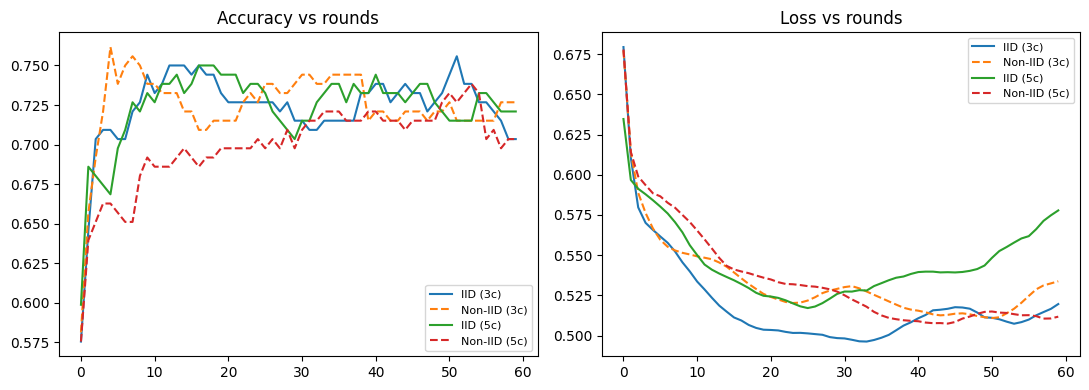

In [20]:
ROUNDS, LOCAL_EPOCHS, LOCAL_BATCH = 60, 3, 16
fedavg_models, fedavg_hists = {}, {}
for n in CLIENT_COUNTS:
    m_iid, h_iid, t_iid = fedavg(clients_by_n[n]['iid'], X_train_s, y_train, ROUNDS, LOCAL_EPOCHS, LOCAL_BATCH,
                                  lr=best_cfg['lr'], l2=best_cfg['l2'], seed=SEED, arch=best_cfg)
    m_non, h_non, t_non = fedavg(clients_by_n[n]['noniid'], X_train_s, y_train, ROUNDS, LOCAL_EPOCHS, LOCAL_BATCH,
                                  lr=best_cfg['lr'], l2=best_cfg['l2'], seed=SEED, arch=best_cfg)
    fedavg_models[n] = {'iid': m_iid, 'noniid': m_non}
    fedavg_hists[n] = {'iid': h_iid, 'noniid': h_non}

fig, axes = plt.subplots(1, 2, figsize=(11,4))
for n in CLIENT_COUNTS:
    axes[0].plot(fedavg_hists[n]['iid']['round'], fedavg_hists[n]['iid'].val_accuracy, label=f'IID ({n}c)')
    axes[0].plot(fedavg_hists[n]['noniid']['round'], fedavg_hists[n]['noniid'].val_accuracy, '--', label=f'Non-IID ({n}c)')
    axes[1].plot(fedavg_hists[n]['iid']['round'], fedavg_hists[n]['iid'].val_loss, label=f'IID ({n}c)')
    axes[1].plot(fedavg_hists[n]['noniid']['round'], fedavg_hists[n]['noniid'].val_loss, '--', label=f'Non-IID ({n}c)')
axes[0].set_title('Accuracy vs rounds'); axes[0].legend(fontsize=8)
axes[1].set_title('Loss vs rounds'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## FedAvg TEST evaluation (3 and 5 clients)

In [21]:
def final_eval(model, tag):
    proba = model.predict_proba(X_test_s); pred=(proba>=0.5).astype(int)
    m = eval_all(y_test, pred, proba); print(tag, m); return m

fedavg_test = {}
for n in CLIENT_COUNTS:
    fedavg_test[(n,'iid')] = final_eval(fedavg_models[n]['iid'], f'FedAvg IID {n}c (test)')
    fedavg_test[(n,'noniid')] = final_eval(fedavg_models[n]['noniid'], f'FedAvg Non-IID {n}c (test)')

FedAvg IID 3c (test) {'accuracy': 0.7034883720930233, 'precision': 0.8333333333333334, 'recall': 0.5494505494505495, 'f1': 0.6622516556291391, 'roc_auc': 0.8102021435354768}
FedAvg Non-IID 3c (test) {'accuracy': 0.7151162790697675, 'precision': 0.8, 'recall': 0.6153846153846154, 'f1': 0.6956521739130435, 'roc_auc': 0.7963641296974631}
FedAvg IID 5c (test) {'accuracy': 0.7209302325581395, 'precision': 0.8028169014084507, 'recall': 0.6263736263736264, 'f1': 0.7037037037037037, 'roc_auc': 0.7906661239994575}
FedAvg Non-IID 5c (test) {'accuracy': 0.6918604651162791, 'precision': 0.7567567567567568, 'recall': 0.6153846153846154, 'f1': 0.6787878787878788, 'roc_auc': 0.7566137566137566}


## Differential Privacy setup (DP-SGD, Abadi et al. 2016)

In [22]:
DELTA = 1e-4
avg_client_size = {n: int(np.mean([len(c) for c in clients_by_n[n]['iid']])) for n in CLIENT_COUNTS}
print("avg client size by N_CLIENTS:", avg_client_size, "| delta:", DELTA)

avg client size by N_CLIENTS: {3: 267, 5: 160} | delta: 0.0001


## DP parameter sweep (real epsilon computed per client count)

In [23]:
privacy_configs = {
    'low_privacy': dict(max_grad_norm=1.5, noise_multiplier=0.4),
    'medium_privacy': dict(max_grad_norm=1.0, noise_multiplier=0.8),
    'strong_privacy': dict(max_grad_norm=0.7, noise_multiplier=1.5),
    'very_strong_privacy': dict(max_grad_norm=0.7, noise_multiplier=4.0),
}
for n in CLIENT_COUNTS:
    for name, cfg in privacy_configs.items():
        eps, alpha = compute_epsilon_federated(avg_client_size[n], min(LOCAL_BATCH,avg_client_size[n]),
                                                cfg['noise_multiplier'], LOCAL_EPOCHS, ROUNDS, DELTA)
        print(f"[{n}c] {name} {cfg} -> epsilon={eps:.2f} (alpha={alpha})")

[3c] low_privacy {'max_grad_norm': 1.5, 'noise_multiplier': 0.4} -> epsilon=3221.09 (alpha=2)
[3c] medium_privacy {'max_grad_norm': 1.0, 'noise_multiplier': 0.8} -> epsilon=50.37 (alpha=2)
[3c] strong_privacy {'max_grad_norm': 0.7, 'noise_multiplier': 1.5} -> epsilon=14.17 (alpha=3)
[3c] very_strong_privacy {'max_grad_norm': 0.7, 'noise_multiplier': 4.0} -> epsilon=4.00 (alpha=6)
[5c] low_privacy {'max_grad_norm': 1.5, 'noise_multiplier': 0.4} -> epsilon=3284.71 (alpha=2)
[5c] medium_privacy {'max_grad_norm': 1.0, 'noise_multiplier': 0.8} -> epsilon=75.84 (alpha=2)
[5c] strong_privacy {'max_grad_norm': 0.7, 'noise_multiplier': 1.5} -> epsilon=19.26 (alpha=2)
[5c] very_strong_privacy {'max_grad_norm': 0.7, 'noise_multiplier': 4.0} -> epsilon=5.26 (alpha=5)


## Federated + DP training (3 and 5 clients x 4 privacy levels)

In [24]:
dp_models, dp_results = {}, {}
for n in CLIENT_COUNTS:
    for name, cfg in privacy_configs.items():
        model, hist, ttime = fedavg(clients_by_n[n]['iid'], X_train_s, y_train, ROUNDS, LOCAL_EPOCHS, LOCAL_BATCH,
                                     lr=best_cfg['lr'], l2=best_cfg['l2'], seed=SEED, arch=best_cfg, dp=True,
                                     max_grad_norm=cfg['max_grad_norm'], noise_multiplier=cfg['noise_multiplier'])
        dp_models[(n,name)] = model
        tm = final_eval(model, f'FedAvg+DP [{n}c, {name}] (test)')
        eps, alpha = compute_epsilon_federated(avg_client_size[n], min(LOCAL_BATCH,avg_client_size[n]),
                                                cfg['noise_multiplier'], LOCAL_EPOCHS, ROUNDS, DELTA)
        tm.update({'epsilon': eps, 'delta': DELTA, 'n_clients': n, 'config': name, 'training_time_sec': ttime})
        dp_results[(n,name)] = tm

FedAvg+DP [3c, low_privacy] (test) {'accuracy': 0.6686046511627907, 'precision': 0.7428571428571429, 'recall': 0.5714285714285714, 'f1': 0.6459627329192547, 'roc_auc': 0.770587437254104}
FedAvg+DP [3c, medium_privacy] (test) {'accuracy': 0.6395348837209303, 'precision': 0.7101449275362319, 'recall': 0.5384615384615384, 'f1': 0.6125, 'roc_auc': 0.7450820784154116}
FedAvg+DP [3c, strong_privacy] (test) {'accuracy': 0.627906976744186, 'precision': 0.7142857142857143, 'recall': 0.4945054945054945, 'f1': 0.5844155844155844, 'roc_auc': 0.7121150454483789}
FedAvg+DP [3c, very_strong_privacy] (test) {'accuracy': 0.5988372093023255, 'precision': 0.6195652173913043, 'recall': 0.6263736263736264, 'f1': 0.6229508196721312, 'roc_auc': 0.6765703432370099}
FedAvg+DP [5c, low_privacy] (test) {'accuracy': 0.7034883720930233, 'precision': 0.7857142857142857, 'recall': 0.6043956043956044, 'f1': 0.6832298136645962, 'roc_auc': 0.7648894315560983}
FedAvg+DP [5c, medium_privacy] (test) {'accuracy': 0.6337209

## DP-FL evaluation summary

In [25]:
dp_results_df = pd.DataFrame(list(dp_results.values()))
dp_results_df.to_csv('outputs/fedavg_dp_results.csv', index=False)
dp_results_df

,accuracy,precision,recall,f1,roc_auc,epsilon,delta,n_clients,config,training_time_sec
0,0.668605,0.742857,0.571429,0.645963,0.770587,3221.086475,0.0001,3,low_privacy,4.531783
1,0.639535,0.710145,0.538462,0.612500,0.745082,50.367063,0.0001,3,medium_privacy,5.268154
2,0.627907,0.714286,0.494505,0.584416,0.712115,14.166417,0.0001,3,strong_privacy,5.294943
3,0.598837,0.619565,0.626374,0.622951,0.676570,3.999976,0.0001,3,very_strong_privacy,5.293885
4,0.703488,0.785714,0.604396,0.683230,0.764889,3284.705662,0.0001,5,low_privacy,5.760225
5,0.633721,0.725806,0.494505,0.588235,0.720662,75.835164,0.0001,5,medium_privacy,5.602446
6,0.616279,0.681159,0.516484,0.587500,0.676977,19.255482,0.0001,5,strong_privacy,5.632037
7,0.569767,0.591398,0.604396,0.597826,0.659476,5.256362,0.0001,5,very_strong_privacy,5.447061


## Final comparison: sklearn ensemble vs Centralized MLP vs FedAvg (3,5) vs FedAvg+DP (3,5)

In [26]:
rows = [
    {'Method':'Best sklearn ensemble (non-federated)', 'N_Clients':'N/A', **{k:sklearn_test_metrics[k] for k in ['accuracy','precision','recall','f1','roc_auc']}, 'Epsilon':'N/A'},
    {'Method':'Centralized MLP (federatable arch)', 'N_Clients':'N/A', **{k:cent_test_metrics[k] for k in ['accuracy','precision','recall','f1','roc_auc']}, 'Epsilon':'N/A'},
]
for n in CLIENT_COUNTS:
    for part in ['iid','noniid']:
        tm = fedavg_test[(n,part)]
        rows.append({'Method':f'FedAvg ({part.upper()})', 'N_Clients':n, **{k:tm[k] for k in ['accuracy','precision','recall','f1','roc_auc']}, 'Epsilon':'N/A'})
for n in CLIENT_COUNTS:
    for name in privacy_configs:
        tm = dp_results[(n,name)]
        rows.append({'Method':f'FedAvg+DP ({name})', 'N_Clients':n, **{k:tm[k] for k in ['accuracy','precision','recall','f1','roc_auc']}, 'Epsilon':round(tm['epsilon'],2)})
final_table = pd.DataFrame(rows)
final_table.to_csv('outputs/final_comparison_table.csv', index=False)
final_table

,Method,N_Clients,accuracy,precision,recall,f1,roc_auc,Epsilon
0,Best sklearn ensemble (non-federated),N/A,0.755814,0.826667,0.681319,0.746988,0.853887,N/A
1,Centralized MLP (federatable arch),N/A,0.744186,0.732673,0.813187,0.770833,0.821869,N/A
2,FedAvg (IID),3,0.703488,0.833333,0.549451,0.662252,0.810202,N/A
3,FedAvg (NONIID),3,0.715116,0.800000,0.615385,0.695652,0.796364,N/A
4,FedAvg (IID),5,0.720930,0.802817,0.626374,0.703704,0.790666,N/A
5,FedAvg (NONIID),5,0.691860,0.756757,0.615385,0.678788,0.756614,N/A
6,FedAvg+DP (low_privacy),3,0.668605,0.742857,0.571429,0.645963,0.770587,3221.09
7,FedAvg+DP (medium_privacy),3,0.639535,0.710145,0.538462,0.612500,0.745082,50.37
8,FedAvg+DP (strong_privacy),3,0.627907,0.714286,0.494505,0.584416,0.712115,14.17
9,FedAvg+DP (very_strong_privacy),3,0.598837,0.619565,0.626374,0.622951,0.676570,4.0


## Privacy-utility analysis (3 vs 5 clients)

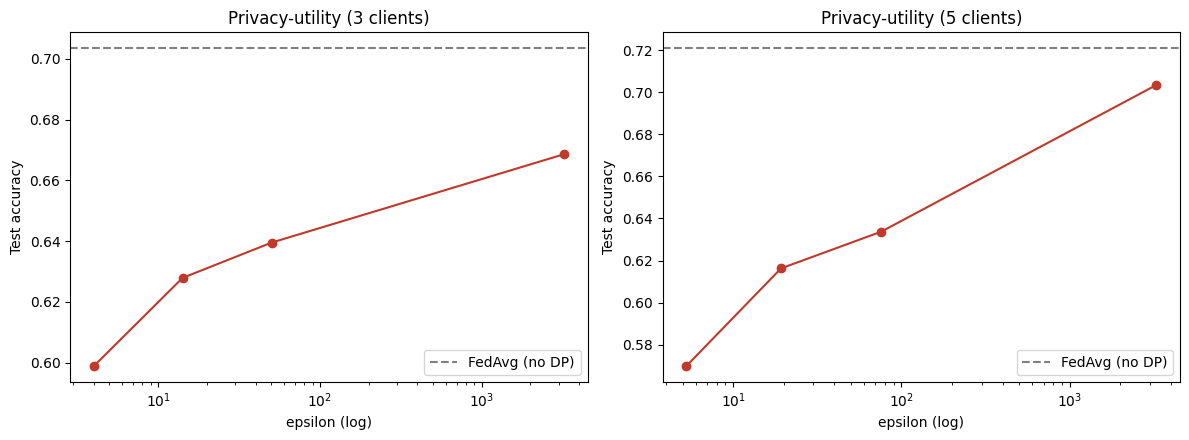

In [27]:
fig, axes = plt.subplots(1, len(CLIENT_COUNTS), figsize=(6*len(CLIENT_COUNTS), 4.5))
for ax, n in zip(axes, CLIENT_COUNTS):
    eps_vals = [dp_results[(n,name)]['epsilon'] for name in privacy_configs]
    acc_vals = [dp_results[(n,name)]['accuracy'] for name in privacy_configs]
    ax.plot(eps_vals, acc_vals, 'o-', color='#c0392b')
    ax.axhline(fedavg_test[(n,'iid')]['accuracy'], ls='--', color='gray', label='FedAvg (no DP)')
    ax.set_xscale('log'); ax.set_xlabel('epsilon (log)'); ax.set_ylabel('Test accuracy')
    ax.set_title(f'Privacy-utility ({n} clients)'); ax.legend()
plt.tight_layout(); plt.show()

## Final visualizations recap
See `plots/` for all EDA, training-curve, confusion-matrix, ROC, client-distribution, and privacy-utility figures.

In [28]:
print('All plots saved under plots/*.png')

All plots saved under plots/*.png


## Save models/results

In [29]:
for n in CLIENT_COUNTS:
    with open(f'outputs/fedavg_model_{n}c_iid.pkl','wb') as f: pickle.dump(fedavg_models[n]['iid'], f)
    with open(f'outputs/fedavg_model_{n}c_noniid.pkl','wb') as f: pickle.dump(fedavg_models[n]['noniid'], f)
    for name in privacy_configs:
        with open(f'outputs/fedavg_dp_model_{n}c_{name}.pkl','wb') as f: pickle.dump(dp_models[(n,name)], f)
print("Saved.")

Saved.


## Final research conclusion

See `research_report.md` for the full write-up: why 90%+ accuracy is not achievable validly on this
dataset, the CV-based comparison table, the 3-vs-5-client effect on FedAvg and FedAvg+DP, and the
privacy/utility trade-off discussion.